# Initial Data Analysis (IDA)
**House Demand Forecasting **

Prüfung der fünf Quelldateien in ihrer ursprünglichen Frequenz und über den vollständigen Dateizeitraum. Keine Imputation, Ausreißerentfernung, Zinsaggregation oder Verknüpfung der Messwerte.

Methodischer Bezug: Kroese et al. (2024), Variablentypen und deskriptive Kennzahlen.

## 1 Bibliotheken und Datenpfad


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

data_dir = Path(r"C:\Users\mmatavela_scalefree\Desktop\House_Demand_Forecasting\daten")

dataset_config = {
    "dom": {
        "file_name": "MEDDAYONMAR53033.csv", "value_column": "MEDDAYONMAR53033",
        "label": "DOM", "frequency": "Monat", "role": "Primäre Zielgröße",
        "region": "King County", "source": "Realtor.com / FRED",
        "unit": "Tage", "variable_type": "metrisch",
    },
    "pending": {
        "file_name": "PENLISCOU53033.csv", "value_column": "PENLISCOU53033",
        "label": "Pending", "frequency": "Monat", "role": "Sekundäre Zielgröße",
        "region": "King County", "source": "Realtor.com / FRED",
        "unit": "Angebote", "variable_type": "diskrete Anzahl",
    },
    "active": {
        "file_name": "ACTLISCOU53033.csv", "value_column": "ACTLISCOU53033",
        "label": "Active", "frequency": "Monat", "role": "Angebotsindikator",
        "region": "King County", "source": "Realtor.com / FRED",
        "unit": "Angebote", "variable_type": "diskrete Anzahl",
    },
    "mortgage_rate": {
        "file_name": "MORTGAGE30US.csv", "value_column": "MORTGAGE30US",
        "label": "Zinsen", "frequency": "Woche", "role": "Finanzierung",
        "region": "USA", "source": "Freddie Mac / FRED",
        "unit": "Prozent", "variable_type": "metrisch",
    },
    "building_permits": {
        "file_name": "Building_Permits_Seattle_2016_2026.csv",
        "value_column": "authorized_units_total",
        "label": "Baugenehmigungen", "frequency": "Monat", "role": "Bautätigkeit",
        "region": "Seattle–Tacoma–Bellevue", "source": "U.S. Census Bureau / BPS",
        "unit": "Wohneinheiten", "variable_type": "diskrete Anzahl",
    },
}

permit_components = [
    "authorized_units_1_unit", "authorized_units_2_units",
    "authorized_units_3_4_units", "authorized_units_5plus_units",
]

## 2 Import und Datenbasis
Fehlwertcodes werden als fehlend eingelesen. Datum und benötigte Messgrößen werden typisiert; ungültige Formate lösen einen Fehler aus.

In [3]:
raw_data = {}
datasets = {}
numeric_columns = {}
overview_rows = []

for dataset_name, config in dataset_config.items():
    raw_frame = pd.read_csv(
        data_dir / config["file_name"], dtype="string",
        na_values=[".", "", "NA", "N/A", "NaN", "NULL", "null"],
        encoding="utf-8-sig",
    )
    raw_data[dataset_name] = raw_frame
    data_frame = raw_frame.copy()
    data_frame["observation_date"] = pd.to_datetime(
        data_frame["observation_date"], format="%Y-%m-%d", errors="raise"
    )
    numeric_columns[dataset_name] = [config["value_column"]]
    if dataset_name == "building_permits":
        numeric_columns[dataset_name] += permit_components
    for column_name in numeric_columns[dataset_name]:
        data_frame[column_name] = pd.to_numeric(
            data_frame[column_name], errors="raise"
        ).astype("float64")

    datasets[dataset_name] = data_frame
    overview_rows.append({
        "Datensatz": config["label"], "Quelle": config["source"],
        "Beginn": data_frame["observation_date"].min().strftime("%m/%Y"),
        "Ende": data_frame["observation_date"].max().strftime("%m/%Y"),
        "Zeilen": len(data_frame), "Frequenz": config["frequency"],
        "Funktion": config["role"], "Raumbezug": config["region"],
    })

data_overview = pd.DataFrame(overview_rows)
display(data_overview)

,Datensatz,Quelle,Beginn,Ende,Zeilen,Frequenz,Funktion,Raumbezug
0,DOM,Realtor.com / FRED,07/2016,09/2026,123,Monat,Primäre Zielgröße,King County
1,Pending,Realtor.com / FRED,11/2016,08/2026,118,Monat,Sekundäre Zielgröße,King County
2,Active,Realtor.com / FRED,07/2016,09/2026,123,Monat,Angebotsindikator,King County
3,Zinsen,Freddie Mac / FRED,04/1971,10/2026,2897,Woche,Finanzierung,USA
4,Baugenehmigungen,U.S. Census Bureau / BPS,01/2016,08/2026,128,Monat,Bautätigkeit,Seattle–Tacoma–Bellevue


## 3 Variablentypen und Duplikate
Ausgewiesen werden die fünf Hauptvariablen, Zeilenduplikate und wiederholte Beobachtungsdate.

In [4]:
variable_rows = []
duplicate_rows = []

for dataset_name, config in dataset_config.items():
    data_frame = datasets[dataset_name]
    variable_rows.append({
        "Variable": config["label"], "Datei": config["file_name"],
        "Messspalte": config["value_column"], "Einheit": config["unit"],
        "Fachlicher Typ": config["variable_type"],
        "Python-Datentyp": str(data_frame[config["value_column"]].dtype),
    })
    duplicate_rows.append({
        "Datensatz": config["label"],
        "Zeilenduplikate": int(raw_data[dataset_name].duplicated(keep=False).sum()),
        "Wiederholte Beobachtungsdaten": int((
            data_frame["observation_date"].notna()
            & data_frame["observation_date"].duplicated(keep=False)
        ).sum()),
    })

variable_overview = pd.DataFrame(variable_rows)
duplicate_summary = pd.DataFrame(duplicate_rows)
display(variable_overview)
display(duplicate_summary)

,Variable,Datei,Messspalte,Einheit,Fachlicher Typ,Python-Datentyp
0,DOM,MEDDAYONMAR53033.csv,MEDDAYONMAR53033,Tage,metrisch,float64
1,Pending,PENLISCOU53033.csv,PENLISCOU53033,Angebote,diskrete Anzahl,float64
2,Active,ACTLISCOU53033.csv,ACTLISCOU53033,Angebote,diskrete Anzahl,float64
3,Zinsen,MORTGAGE30US.csv,MORTGAGE30US,Prozent,metrisch,float64
4,Baugenehmigungen,Building_Permits_Seattle_2016_2026.csv,authorized_units_total,Wohneinheiten,diskrete Anzahl,float64


,Datensatz,Zeilenduplikate,Wiederholte Beobachtungsdaten
0,DOM,0,0
1,Pending,0,0
2,Active,0,0
3,Zinsen,0,0
4,Baugenehmigungen,0,0


## 4 Fehlende Werte und Pending-Anfangssegment

Die Tabelle zeigt die fehlenden Messwerte und Datumsangaben der fünf Datensätze. Das Säulendiagramm stellt zusätzlich die Pending-Werte von November 2016 bis September 2017 dar.

Der fehlende Messwert im Juni 2017 wird von vorhandenen Nullwerten unterschieden. Es werden keine Werte ersetzt oder entfernt.


,Datensatz,Zeilen,Fehlende Messwerte,Fehlende Messwerte (%),Fehlendes Datum
0,DOM,123,0,0.00,0
1,Pending,118,1,0.85,0
2,Active,123,0,0.00,0
3,Zinsen,2897,0,0.00,0
4,Baugenehmigungen,128,0,0.00,0


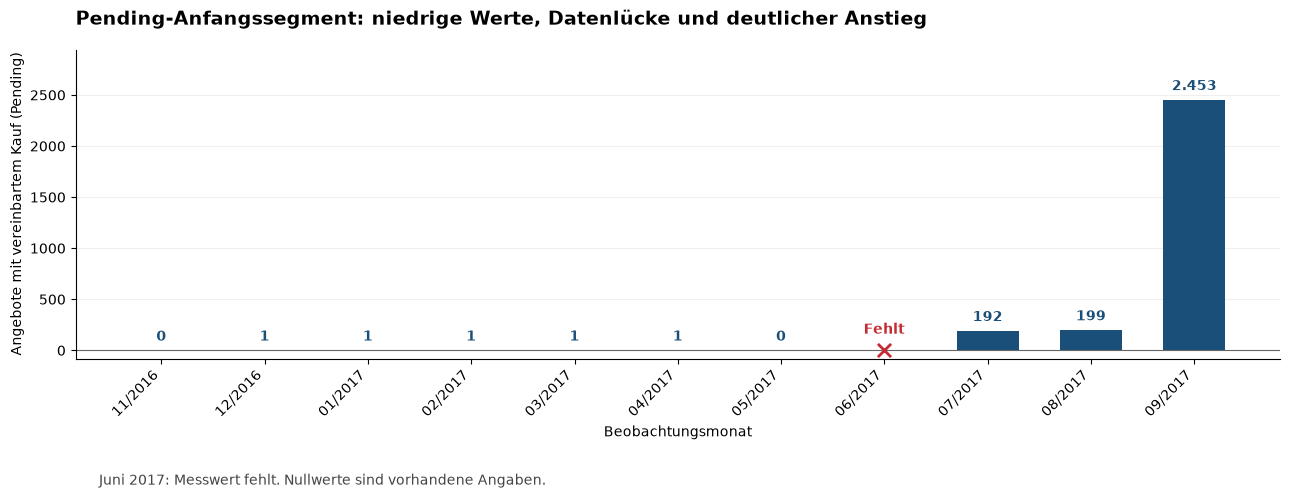

In [ ]:
import matplotlib.pyplot as plt

# Fehlwertübersicht aller fünf Datensätze.
missing_rows = []

for dataset_name, config in dataset_config.items():
    data_frame = datasets[dataset_name]
    values = data_frame[config["value_column"]]

    missing_rows.append({
        "Datensatz": config["label"],
        "Zeilen": len(data_frame),
        "Fehlende Messwerte": int(values.isna().sum()),
        "Fehlende Messwerte (%)": round(values.isna().mean() * 100, 2),
        "Fehlendes Datum": int(data_frame["observation_date"].isna().sum()),
    })

missing_summary = pd.DataFrame(missing_rows)
display(missing_summary)

# Pending-AnfangssegmentSeptember 2017.

pending_values = (
    datasets["pending"]
    .set_index("observation_date")["PENLISCOU53033"]
    .sort_index()
    .reindex(pd.date_range("2016-11-01", "2017-09-01", freq="MS"))
)

month_positions = np.arange(len(pending_values))
available_mask = pending_values.notna().to_numpy()

fig, axis = plt.subplots(figsize=(13, 5))

axis.bar(
    month_positions[available_mask],
    pending_values.loc[pending_values.notna()],
    width=0.6,
    color="#194F78",
)


for position, value in enumerate(pending_values):
    if pd.isna(value):
        axis.scatter(
            position, 0,
            marker="x", s=90, linewidths=2,
            color="#C42B32", zorder=3,
        )
        axis.annotate(
            "Fehlt",
            xy=(position, 0),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            color="#C42B32",
            fontweight="bold",
        )
    else:
        axis.annotate(
            f"{value:,.0f}".replace(",", "."),
            xy=(position, value),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            color="#194F78",
            fontweight="bold",
        )

axis.set_title(
    "Pending-Anfangssegment: niedrige Werte, Datenlücke und deutlicher Anstieg",
    loc="left",
    fontsize=14,
    fontweight="bold",
    pad=18,
)
axis.set_xlabel("Beobachtungsmonat")
axis.set_ylabel("Angebote mit vereinbartem Kauf (Pending)")
axis.set_xticks(month_positions)
axis.set_xticklabels(
    pending_values.index.strftime("%m/%Y"),
    rotation=45,
    ha="right",
)
axis.set_ylim(-80, pending_values.max() * 1.2)
axis.axhline(0, color="#666666", linewidth=0.8)
axis.grid(axis="y", alpha=0.2)
axis.set_axisbelow(True)
axis.spines[["top", "right"]].set_visible(False)

fig.text(
    0.08, 0.02,
    "Juni 2017: Messwert fehlt. Nullwerte sind vorhandene Angaben. "
    ,
    fontsize=10,
    color="#444444",
)

fig.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

## 5 Deskriptive Kennzahlen
Kennzahlen über den jeweiligen Dateizeitraum. „Anzahl Zahlenwerte“ zählt nicht fehlende Werte.Die Summe der quadrierten Abweichungen vom Mittelwert wird durch n − 1 geteilt und anschließend die Quadratwurzel gezogen. Dabei ist n die Anzahl vorhandener Zahlenwerte. Der P-Parameter ddof=1 („Delta Degrees of Freedom“) legt diese Korrektur des Nenners fest.

Die Pending-Kennzahlen enthalten das auffällige Anfangssegment.

In [7]:
statistics_rows = []

for dataset_name, config in dataset_config.items():
    values = datasets[dataset_name][config["value_column"]]
    statistics_rows.append({
        "Variable": f'{config["label"]} · {config["unit"]}',
        "Anzahl Zahlenwerte": int(values.count()),
        "Minimum": values.min(), "Median": values.median(),
        "Maximum": values.max(), "Mittelwert": values.mean(),
        "Standardabweichung": values.std(ddof=1),
    })

descriptive_statistics = pd.DataFrame(statistics_rows)
display(descriptive_statistics.round(2))

,Variable,Anzahl Zahlenwerte,Minimum,Median,Maximum,Mittelwert,Standardabweichung
0,DOM · Tage,123,9.00,33.00,74.00,35.58,13.54
1,Pending · Angebote,117,0.00,2346.00,4177.00,2248.68,901.06
2,Active · Angebote,123,746.00,2849.00,7611.00,3167.72,1465.52
3,Zinsen · Prozent,2897,2.65,7.21,18.63,7.68,3.18
4,Baugenehmigungen · Wohneinheiten,128,759.00,1900.50,3955.00,1931.81,615.72


## 6 Plausibilität und Konsistenz
Prüfung negativer und unendlicher Werte sowie nicht ganzzahliger Anzahlen. Bei den Baugenehmigungen (Building-Permits) werden Gesamtwert und vier Wohneinheiten-Kategorien verglichen. Keine Ausreißerentfernung.

In [ ]:
plausibility_rows = []

for dataset_name, config in dataset_config.items():
    for column_name in numeric_columns[dataset_name]:
        values = datasets[dataset_name][column_name]
        finite_values = values[np.isfinite(values)]
        is_count = config["variable_type"] == "diskrete Anzahl"
        plausibility_rows.append({
            "Datensatz": config["label"], "Messspalte": column_name,
            "Negative Werte": int(values.lt(0).sum()),
            "Unendliche Werte": int(np.isinf(values).sum()),
            "Nicht ganzzahlige Anzahlen": (
                int(finite_values.mod(1).ne(0).sum()) if is_count else pd.NA
            ),
        })

plausibility_summary = pd.DataFrame(plausibility_rows)
permit_data = datasets["building_permits"]
permit_columns = ["authorized_units_total"] + permit_components
complete_permit_rows = permit_data[permit_columns].notna().all(axis=1)
permit_component_sum = permit_data[permit_components].sum(axis=1, min_count=4)
matching_permit_rows = complete_permit_rows & permit_component_sum.eq(
    permit_data["authorized_units_total"]
)
permit_consistency = pd.DataFrame([{
    "Monate insgesamt": len(permit_data),
    "Vollständig prüfbare Monate": int(complete_permit_rows.sum()),
    "Summe entspricht Gesamtwert": int(matching_permit_rows.sum()),
    "Abweichungen": int((complete_permit_rows & ~matching_permit_rows).sum()),
}])

display(plausibility_summary)
display(permit_consistency)

## 7 Zinsen im gemeinsamen Zeitraum
Ergänzende Zinskennzahlen innerhalb der zeitlichen Schnittmenge der fünf Dateien. Die Monatsgrenzen werden aus den Dateien ermittelt. Die Zinsen bleiben Wochenwerte.

In [ ]:
common_start = max(
    data_frame["observation_date"].min().to_period("M")
    for data_frame in datasets.values()
)
common_end = min(
    data_frame["observation_date"].max().to_period("M")
    for data_frame in datasets.values()
)

mortgage_data = datasets["mortgage_rate"]
mortgage_months = mortgage_data["observation_date"].dt.to_period("M")
common_mortgage_values = mortgage_data.loc[
    mortgage_months.between(common_start, common_end), "MORTGAGE30US",
]
common_mortgage_statistics = pd.DataFrame([{
    "Zeitraum": f"{common_start} bis {common_end}",
    "Anzahl Zahlenwerte": int(common_mortgage_values.count()),
    "Minimum (%)": common_mortgage_values.min(),
    "Median (%)": common_mortgage_values.median(),
    "Mittelwert (%)": common_mortgage_values.mean(),
    "Maximum (%)": common_mortgage_values.max(),
}])
display(common_mortgage_statistics.round(2))